In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [36]:

movies = pd.read_csv("../dataset/processed/movieverse_master_dataset_clean.csv")

print(movies.shape)

movies.head()

C:\Users\HARIOM SUTHAR\AppData\Local\Temp\ipykernel_15688\2831584630.py:1: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  movies = pd.read_csv("../dataset/processed/movieverse_master_dataset_clean.csv")


(570748, 16)


,movie_id,title,release_year,tagline,overview,runtime_minutes,avg_rating,genres,main_cast,poster_url,director,producer,languages,themes,countries,studios
0,1000001,Barbie,2023.0,She's everything. He's just Ken.,Barbie and Ken are having the time of their li...,114.0,3.86,Comedy | Adventure,Margot Robbie as Barbie | Ryan Gosling as Ken ...,https://a.ltrbxd.com/resized/film-poster/2/7/7...,Greta Gerwig,Tom Ackerley | Margot Robbie | Robbie Brenner,English,Humanity and the world around us | Crude humor...,UK | USA,LuckyChap Entertainment | Heyday Films | NB/GG...
1,1000002,Parasite,2019.0,Act like you own the place.,"All unemployed, Ki-taek's family takes peculia...",133.0,4.56,Comedy | Thriller | Drama,Song Kang-ho as Kim Ki-taek | Lee Sun-kyun as ...,https://a.ltrbxd.com/resized/film-poster/4/2/6...,Bong Joon-ho,Jang Young-hwan | Kwak Sin-ae | Moon Yang-kwon,Korean | English | German,Humanity and the world around us | Intense vio...,South Korea,Barunson E&A
2,1000003,Everything Everywhere All at Once,2022.0,The universe is so much bigger than you realize.,An aging Chinese immigrant is swept up in an i...,140.0,4.30,Science Fiction | Adventure | Comedy | Action,Michelle Yeoh as Evelyn Wang | Ke Huy Quan as ...,https://a.ltrbxd.com/resized/film-poster/4/7/4...,Daniel Scheinert | Daniel Kwan,Joe Russo | Anthony Russo | Jonathan Wang,English | Cantonese | Chinese,Humanity and the world around us | Moving rela...,USA,IAC Films | AGBO | Ley Line Entertainment
3,1000004,Fight Club,1999.0,Mischief. Mayhem. Soap.,A ticking-time-bomb insomniac and a slippery s...,139.0,4.27,Drama,Edward Norton as Narrator | Brad Pitt as Tyler...,https://a.ltrbxd.com/resized/film-poster/5/1/5...,David Fincher,Ross Grayson Bell | Ceán Chaffin | Art Linson,English,Intense violence and sexual transgression | Hu...,Germany | USA,Fox 2000 Pictures | Regency Enterprises | The ...
4,1000005,La La Land,2016.0,Here's to the fools who dream.,"Mia, an aspiring actress, serves lattes to mov...",129.0,4.09,Drama | Comedy | Music | Romance,Ryan Gosling as Sebastian | Emma Stone as Mia ...,https://a.ltrbxd.com/resized/film-poster/2/4/0...,Damien Chazelle,Jordan Horowitz | Fred Berger | Marc Platt,English,Song and dance | Humanity and the world around...,Hong Kong | USA,Summit Entertainment | Black Label Media | Gil...


In [37]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 570748 entries, 0 to 570747
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   movie_id         570748 non-null  int64  
 1   title            570740 non-null  object 
 2   release_year     514419 non-null  float64
 3   tagline          96105 non-null   object 
 4   overview         570748 non-null  object 
 5   runtime_minutes  389178 non-null  float64
 6   avg_rating       74215 non-null   float64
 7   genres           429424 non-null  object 
 8   main_cast        570748 non-null  object 
 9   poster_url       477317 non-null  object 
 10  director         463916 non-null  object 
 11  producer         570748 non-null  object 
 12  languages        570748 non-null  object 
 13  themes           23618 non-null   object 
 14  countries        570748 non-null  object 
 15  studios          570748 non-null  object 
dtypes: float64(3), int64(1), object(12)
me

In [38]:
movies.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
movie_id,570748.0,NaN,NaN,NaN,1445828.352893,281975.561592,1000001.0,1190777.75,1433965.5,1695717.75,1941597.0
title,570740,504044,Home,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,514419.0,NaN,NaN,NaN,1997.069325,26.33304,1890.0,1983.0,2007.0,2017.0,2031.0
tagline,96105,94119,Cert 18,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
overview,570748,428614,Overview not available.,132489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runtime_minutes,389178.0,NaN,NaN,NaN,96.792401,29.24572,60.0,81.0,90.0,104.0,300.0
avg_rating,74215.0,NaN,NaN,NaN,3.206667,0.429211,0.88,2.96,3.26,3.49,4.69
genres,429424,12880,Drama,71502,NaN,NaN,NaN,NaN,NaN,NaN,NaN
main_cast,570748,419539,Cast information unavailable,139581,NaN,NaN,NaN,NaN,NaN,NaN,NaN
poster_url,477317,476574,https://a.ltrbxd.com/resized/film-poster/9/1/1...,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### missing values

In [39]:
missing = pd.DataFrame({
    "Missing Count": movies.isnull().sum(),
    "Missing %": round(movies.isnull().mean()*100,2)
})

missing = missing.sort_values("Missing %", ascending=False)

missing

,Missing Count,Missing %
themes,547130,95.86
avg_rating,496533,87.00
tagline,474643,83.16
runtime_minutes,181570,31.81
genres,141324,24.76
director,106832,18.72
poster_url,93431,16.37
release_year,56329,9.87
overview,0,0.00
movie_id,0,0.00


### Missing Value Bar Chart

#### Most missing values are present in themes, average ratings, tagline, and producer information.
#### Core information such as movie title, movie ID, language, and release year is largely complete, making the dataset suitable for recommendation and search.

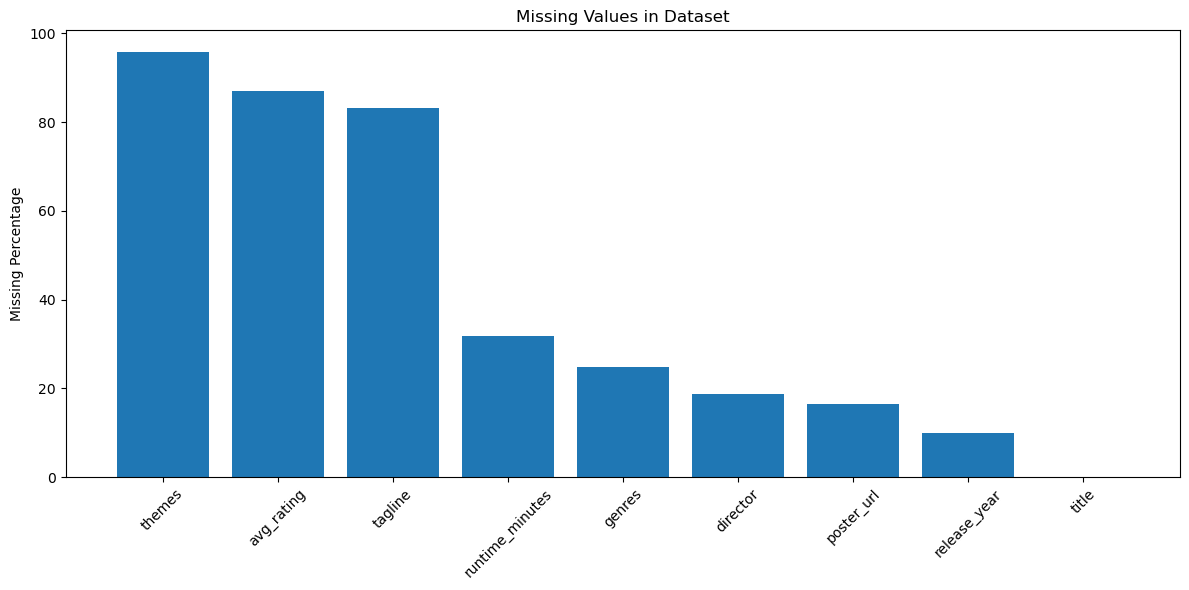

In [40]:
missing = missing[missing["Missing Count"] > 0]

plt.figure(figsize=(12,6))

plt.bar(
    missing.index,
    missing["Missing %"]
)

plt.xticks(rotation=45)

plt.ylabel("Missing Percentage")

plt.title("Missing Values in Dataset")

plt.tight_layout()

plt.show()

### movie released per  year

#### Movie production has increased significantly after the year 2000, with a rapid rise after 2010. The dataset also contains historical movies dating back to the late 1800s.

In [41]:
year_count = (
    movies["release_year"]
    .value_counts()
    .sort_index()
)

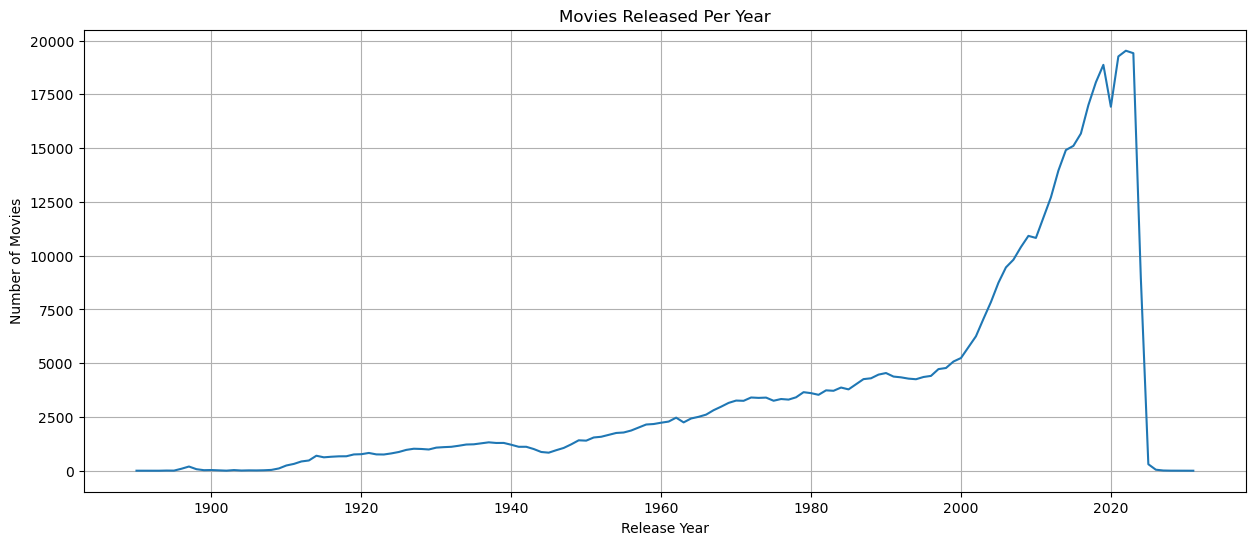

In [42]:
plt.figure(figsize=(15,6))

plt.plot(
    year_count.index,
    year_count.values
)

plt.xlabel("Release Year")

plt.ylabel("Number of Movies")

plt.title("Movies Released Per Year")

plt.grid(True)

plt.show()

### runtime distribution 

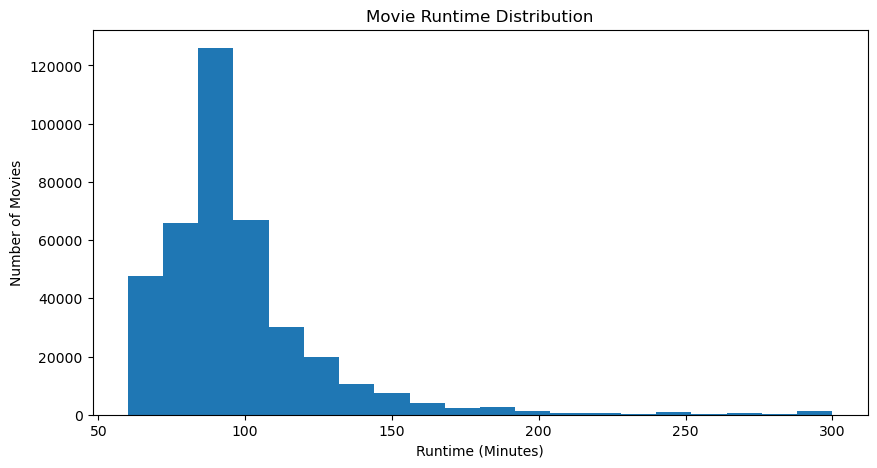

In [43]:
plt.figure(figsize=(10,5))

plt.hist(
    movies["runtime_minutes"].dropna(),
    bins=20
)

plt.xlabel("Runtime (Minutes)")

plt.ylabel("Number of Movies")

plt.title("Movie Runtime Distribution")

plt.show()

### Average Rating Distribution

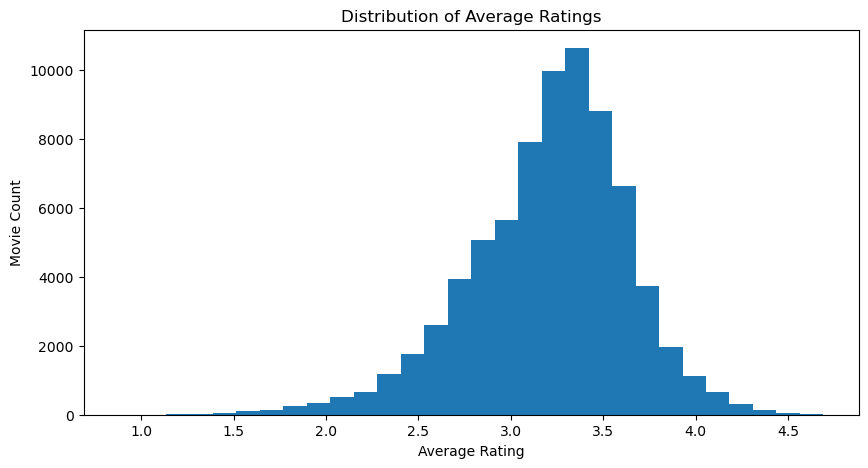

In [46]:
plt.figure(figsize=(10,5))

plt.hist(
    movies["avg_rating"].dropna(),
    bins=30
)

plt.xlabel("Average Rating")

plt.ylabel("Movie Count")

plt.title("Distribution of Average Ratings")

plt.show()

### genres analysis

In [47]:
genre_df = (
    movies["genres"]
    .dropna()
    .str.split(" \\| ")
    .explode()
)

genre_df.head()

0       Comedy
0    Adventure
1       Comedy
1     Thriller
1        Drama
Name: genres, dtype: object

### Top Genres

In [48]:
top_genres = genre_df.value_counts().head(20)

top_genres

genres
Drama              167940
Comedy              99416
Documentary         82311
Romance             43466
Thriller            37291
Action              35391
Horror              34274
Music               32259
Crime               29985
TV Movie            20733
Family              18671
Adventure           18586
Mystery             15164
Fantasy             13431
Animation           13121
History             12882
Science Fiction     12520
War                  8483
Western              5785
Name: count, dtype: int64

### Graph

#### Drama and Comedy are dominate the dataset, followed by genres such as Action, Thriller, and Romance. This indicates that the dataset covers a broad range of mainstream movies.

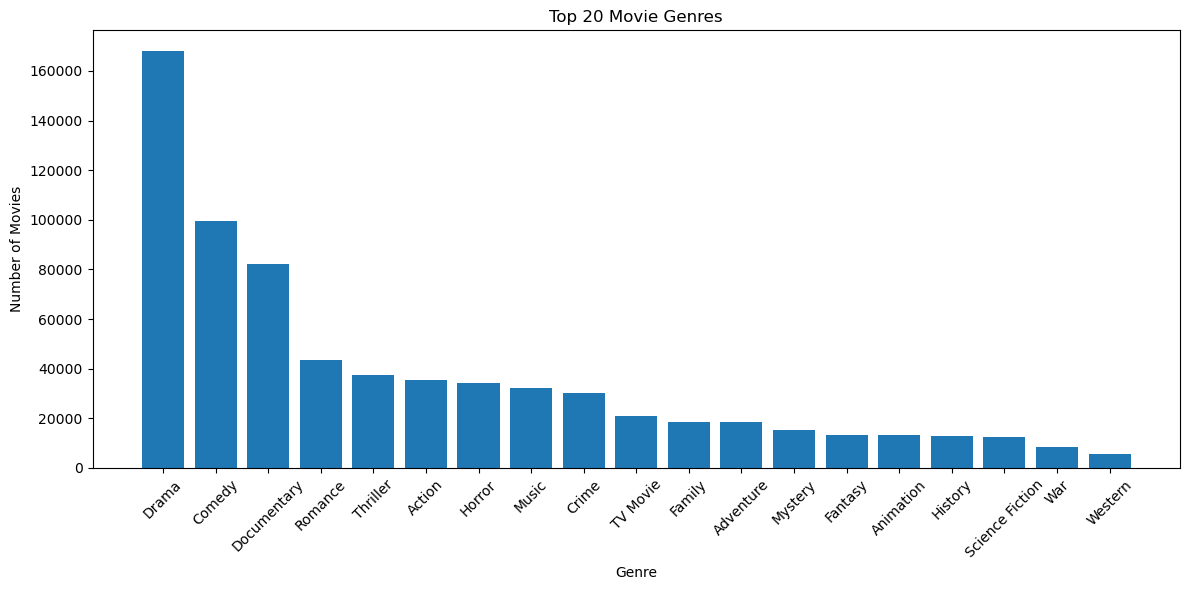

In [49]:
plt.figure(figsize=(12,6))

plt.bar(
    top_genres.index,
    top_genres.values
)

plt.xticks(rotation=45)

plt.xlabel("Genre")

plt.ylabel("Number of Movies")

plt.title("Top 20 Movie Genres")

plt.tight_layout()

plt.show()

### Language Analysis 

In [51]:
language_df = (
    movies["languages"]
    .dropna()
    .str.split(" \\| ")
    .explode()
)

top_languages = language_df.value_counts().head(20)

top_languages

languages
English       235722
French         43886
Spanish        42814
German         41164
Japanese       31704
Chinese        25169
Italian        20473
Portuguese     18038
Russian        16945
Unknown        10702
Korean         10372
Arabic          9207
Hindi           8175
Czech           6923
Turkish         6821
Tagalog         5895
Dutch           5887
Cantonese       5706
Swedish         5306
Tamil           5007
Name: count, dtype: int64

###  Graph

#### English dominates the dataset, while several regional and international languages such as French, Japanese, Hindi, Korean, and Spanish are also well represented.

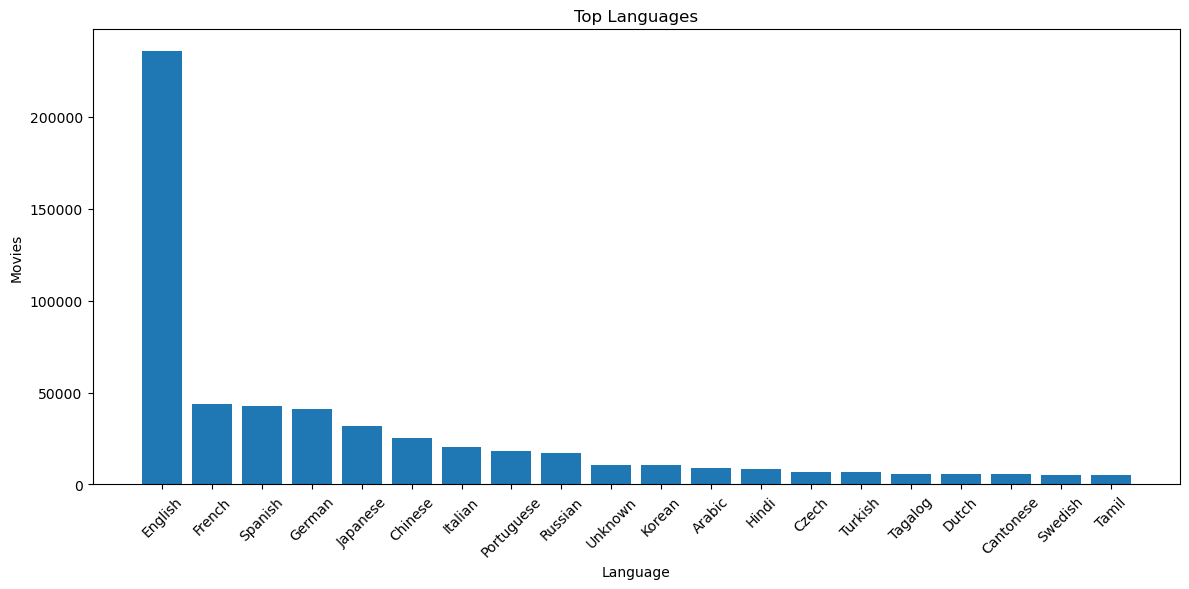

In [53]:
plt.figure(figsize=(12,6))

plt.bar(
    top_languages.index,
    top_languages.values
)

plt.xticks(rotation=45)

plt.xlabel("Language")

plt.ylabel("Movies")

plt.title("Top Languages")

plt.tight_layout()

plt.show()

### Country Analysis 


In [55]:
country_df = (
    movies["countries"]
    .dropna()
    .str.split(" \\| ")
    .explode()
)

top_countries = country_df.value_counts().head(20)

top_countries

countries
Unknown               179433
USA                   103130
Germany                32235
Japan                  29324
France                 28722
UK                     23371
India                  20164
Italy                  15167
Canada                 12051
Spain                  11628
China                  10850
Mexico                  9880
Brazil                  9581
South Korea             7912
USSR                    6562
Hong Kong               6480
Argentina               6393
Russian Federation      6269
Philippines             5921
Czechoslovakia          5395
Name: count, dtype: int64

### Graph

#### The United States contributes the highest number of movies, followed by countries such as the United Kingdom, France, Japan, India, and South Korea.(In dataset the country name is missing in many row , it indicate as "Unknown")

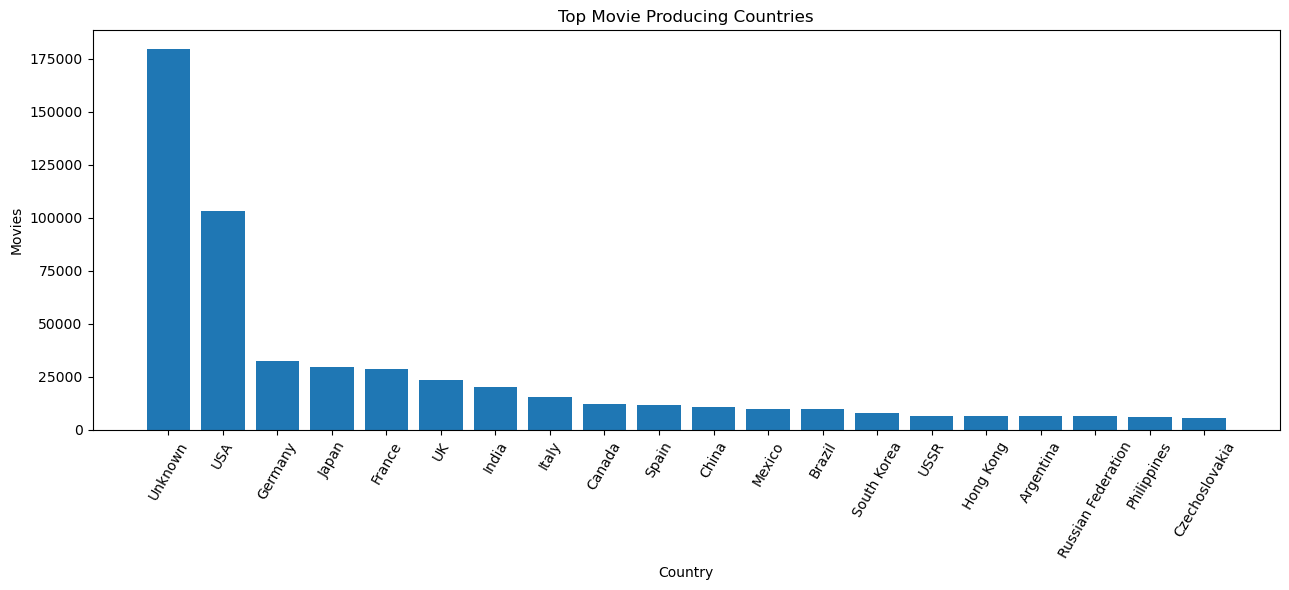

In [57]:
plt.figure(figsize=(13,6))

plt.bar(
    top_countries.index,
    top_countries.values
)

plt.xticks(rotation=60)

plt.xlabel("Country")

plt.ylabel("Movies")

plt.title("Top Movie Producing Countries")

plt.tight_layout()

plt.show()

### movie released per decade

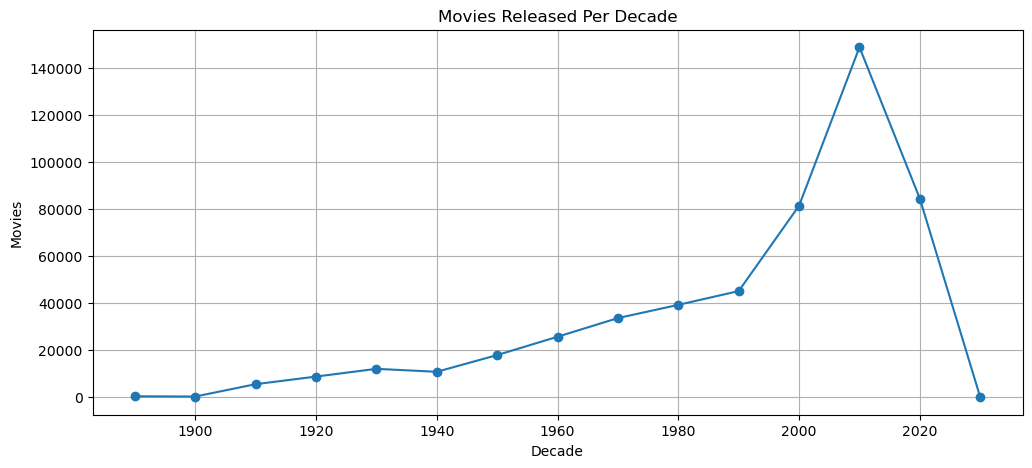

In [59]:
movies["decade"] = (movies["release_year"] // 10) * 10

decade_count = (
    movies["decade"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12,5))
plt.plot(decade_count.index, decade_count.values, marker="o")
plt.xlabel("Decade")
plt.ylabel("Movies")
plt.title("Movies Released Per Decade")
plt.grid(True)
plt.show()

### Average rating by genres

In [61]:
genre_rating = (
    movies.dropna(subset=["genres","avg_rating"])
    .assign(genres=lambda x: x["genres"].str.split(" \\| "))
    .explode("genres")
)

rating_by_genre = (
    genre_rating.groupby("genres")["avg_rating"]
    .mean()
    .sort_values(ascending=False)
)

rating_by_genre.head(15)

genres
Documentary    3.528693
Music          3.412497
History        3.391681
War            3.372760
Drama          3.307976
Animation      3.283726
Western        3.279991
Crime          3.225691
Romance        3.184905
Mystery        3.138380
Comedy         3.137353
Fantasy        3.093882
Adventure      3.081532
TV Movie       3.061650
Family         3.053883
Name: avg_rating, dtype: float64

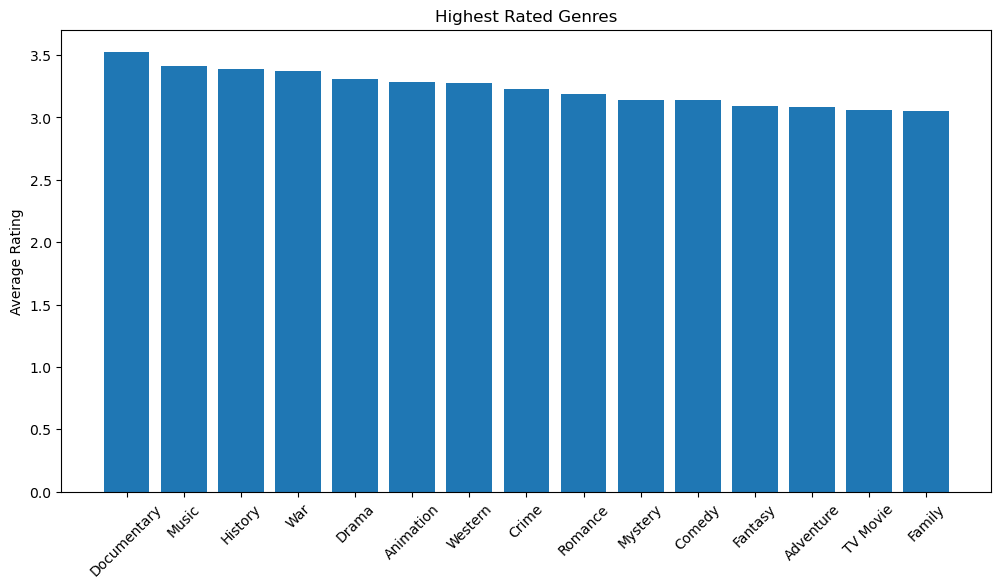

In [65]:
plt.figure(figsize=(12,6))

plt.bar(
    rating_by_genre.head(15).index,
    rating_by_genre.head(15).values
)

plt.xticks(rotation=45)

plt.ylabel("Average Rating")

plt.title("Highest Rated Genres")

plt.show()


In [66]:
### Runtime by Genre

In [67]:
runtime_genre = (
    movies.dropna(subset=["genres","runtime_minutes"])
    .assign(genres=lambda x:x["genres"].str.split(" \\| "))
    .explode("genres")
)

runtime_by_genre = (
    runtime_genre.groupby("genres")["runtime_minutes"]
    .mean()
    .sort_values(ascending=False)
)

runtime_by_genre.head(15)

genres
Animation          107.165437
History            106.660228
Music              104.222691
Action             101.930162
War                101.870393
Drama              101.205406
Romance            100.721617
Mystery             99.942439
Crime               99.100073
Thriller            98.071453
Comedy              96.952895
Adventure           96.345825
Fantasy             95.662300
Family              95.261581
Science Fiction     94.167349
Name: runtime_minutes, dtype: float64

In [72]:
### Top 10 Higest rated movies

In [74]:
highest_rated = (
    movies[
        ["title", "avg_rating", "release_year"]
    ]
    .dropna()
    .sort_values(
        "avg_rating",
        ascending=False
    )
    .head(10)
)

highest_rated

,title,avg_rating,release_year
856,Harakiri,4.69,1962.0
1223,Stop Making Sense,4.68,1984.0
4160,Radiohead: In Rainbows – From the Basement,4.66,2008.0
3155,No Half Measures: Creating the Final Season of...,4.65,2013.0
430,Come and See,4.64,1985.0
238,12 Angry Men,4.62,1957.0
5539,Planet Earth II,4.61,2016.0
943,Over the Garden Wall,4.61,2014.0
1987,National Theatre Live: Fleabag,4.60,2019.0
1231,Twin Peaks,4.60,1989.0


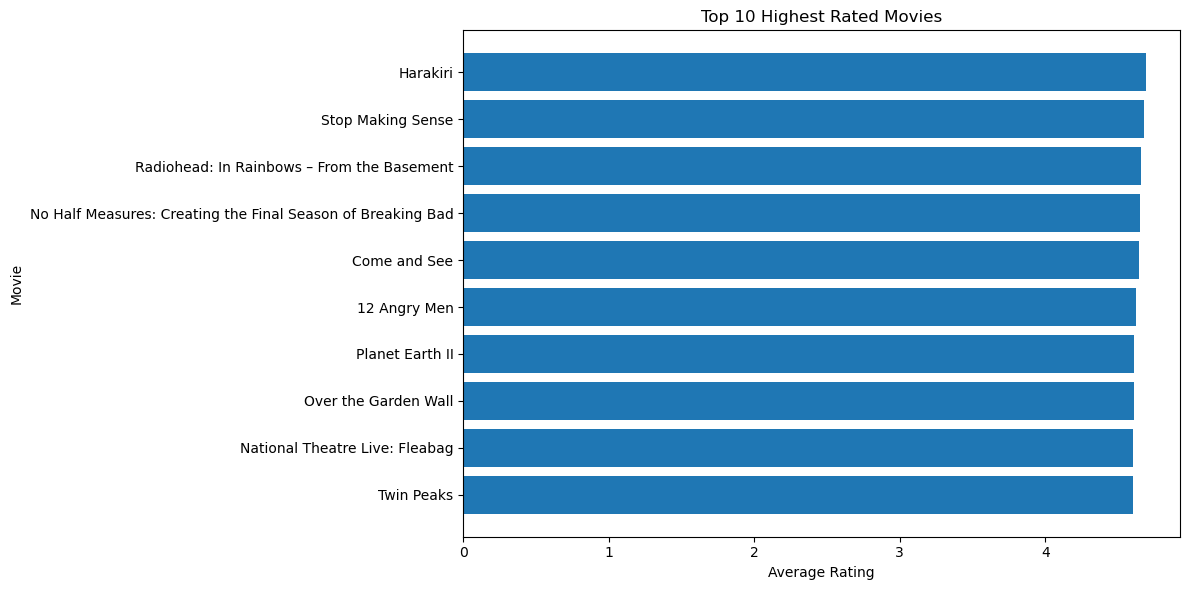

In [75]:
plt.figure(figsize=(12,6))

plt.barh(
    highest_rated["title"],
    highest_rated["avg_rating"]
)

plt.xlabel("Average Rating")
plt.ylabel("Movie")
plt.title("Top 10 Highest Rated Movies")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

### Top 10 most common genre combination  

#### Drama, Comedy, Thriller, Romance and Action frequently appear together, showing that movies often belong to multiple genres rather than a single category.

In [76]:
genre_combo = (
    movies["genres"]
    .dropna()
    .value_counts()
    .head(10)
)

genre_combo

genres
Drama              71502
Documentary        65544
Comedy             40942
Music              16109
Horror             13287
Drama | Romance     6561
Comedy | Drama      6276
Romance | Drama     5974
Drama | Comedy      5829
Action              5405
Name: count, dtype: int64

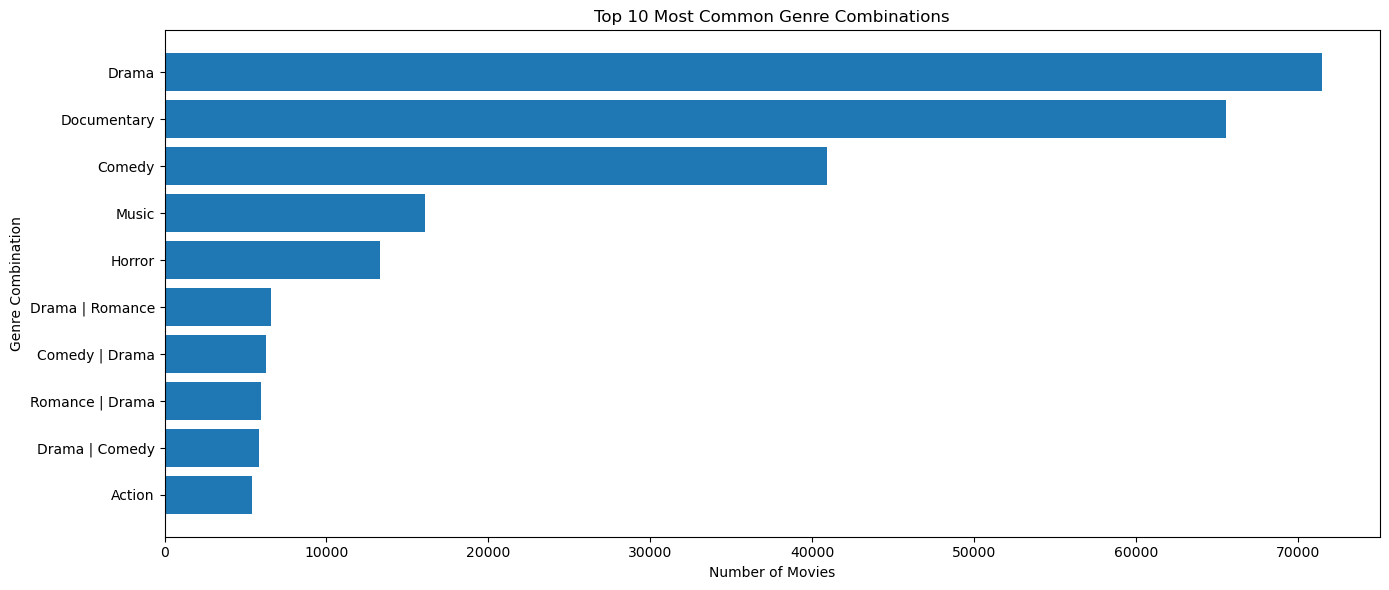

In [77]:
plt.figure(figsize=(14,6))

plt.barh(
    genre_combo.index,
    genre_combo.values
)

plt.xlabel("Number of Movies")
plt.ylabel("Genre Combination")

plt.title("Top 10 Most Common Genre Combinations")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

### Movies by Runtime Category

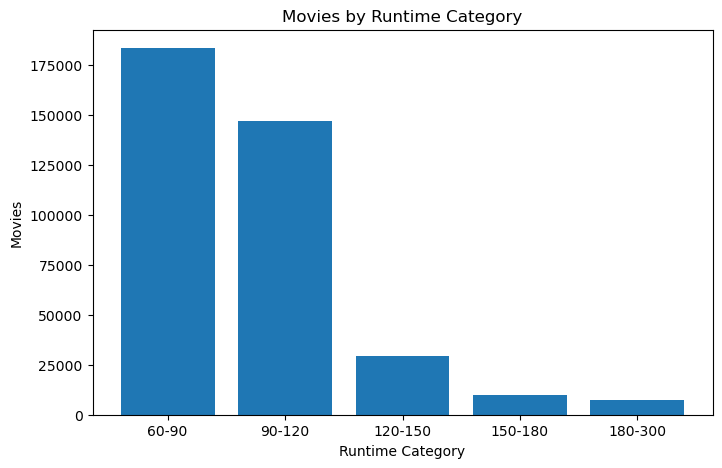

In [78]:
runtime_category = pd.cut(
    movies["runtime_minutes"],
    bins=[60,90,120,150,180,300],
    labels=[
        "60-90",
        "90-120",
        "120-150",
        "150-180",
        "180-300"
    ]
)

runtime_count = runtime_category.value_counts().sort_index()

plt.figure(figsize=(8,5))

plt.bar(
    runtime_count.index.astype(str),
    runtime_count.values
)

plt.xlabel("Runtime Category")
plt.ylabel("Movies")

plt.title("Movies by Runtime Category")

plt.show()

In [79]:
### Top 10 Most Prolific Directors

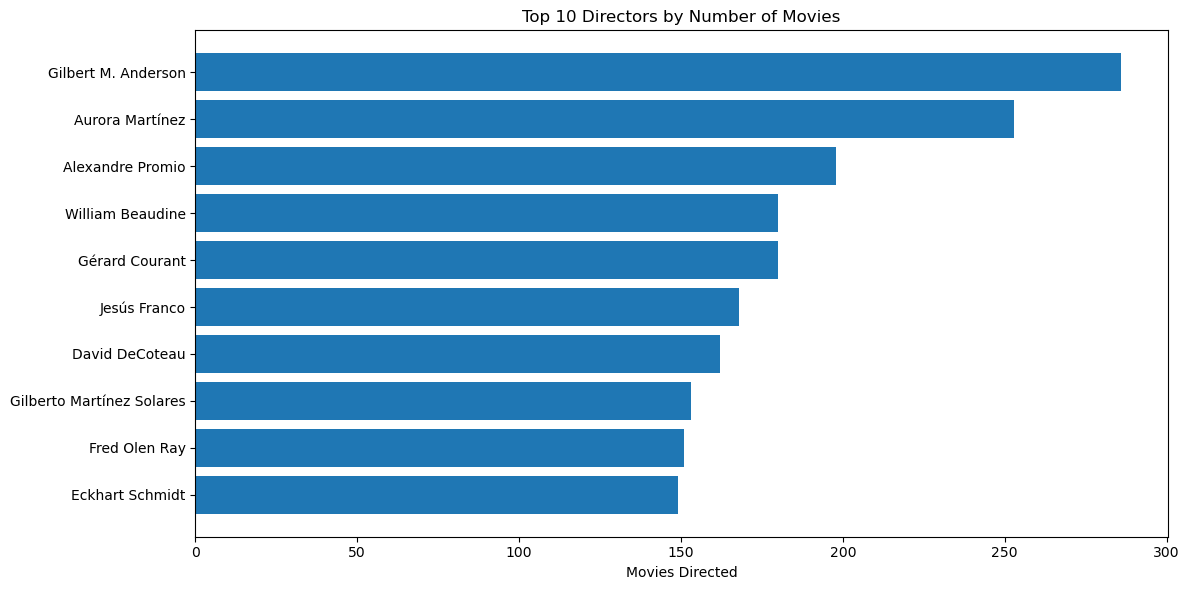

In [80]:
director_df = (
    movies["director"]
    .dropna()
    .str.split(" \\| ")
    .explode()
)

top_directors = director_df.value_counts().head(10)

plt.figure(figsize=(12,6))

plt.barh(
    top_directors.index,
    top_directors.values
)

plt.xlabel("Movies Directed")

plt.title("Top 10 Directors by Number of Movies")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [81]:
### Top 15 Actors by Movie Count

In [82]:
actor_df = (
    movies["main_cast"]
    .dropna()
    .str.split(" \\| ")
    .explode()
)

# Sirf actor ka naam nikalo
actor_df = actor_df.str.split(" as ").str[0]

top_actors = actor_df.value_counts().head(15)

top_actors

main_cast
Cast information unavailable    139581
Jagathy Sreekumar                  494
Eric Roberts                       469
Brahmanandam                       465
Mammootty                          422
Nassar                             400
Nedumudi Venu                      347
Mohanlal                           345
Prakash Raj                        332
Shakti Kapoor                      309
Mithun Chakraborty                 295
Manorama                           291
Anupam Kher                        286
Siddique                           279
Cüneyt Arkın                       264
Name: count, dtype: int64

In [87]:
actor_df = (
    movies["main_cast"]
    .dropna()
)

# Placeholder remove
actor_df = actor_df[
    actor_df != "Cast information unavailable"
]

# Split actors
actor_df = actor_df.str.split(" \\| ").explode()


actor_df = actor_df.str.split(" as ").str[0]

top_actors = actor_df.value_counts().head(15)

top_actors

main_cast
Jagathy Sreekumar     494
Eric Roberts          469
Brahmanandam          465
Mammootty             422
Nassar                400
Nedumudi Venu         347
Mohanlal              345
Prakash Raj           332
Shakti Kapoor         309
Mithun Chakraborty    295
Manorama              291
Anupam Kher           286
Siddique              279
Cüneyt Arkın          264
Innocent              260
Name: count, dtype: int64

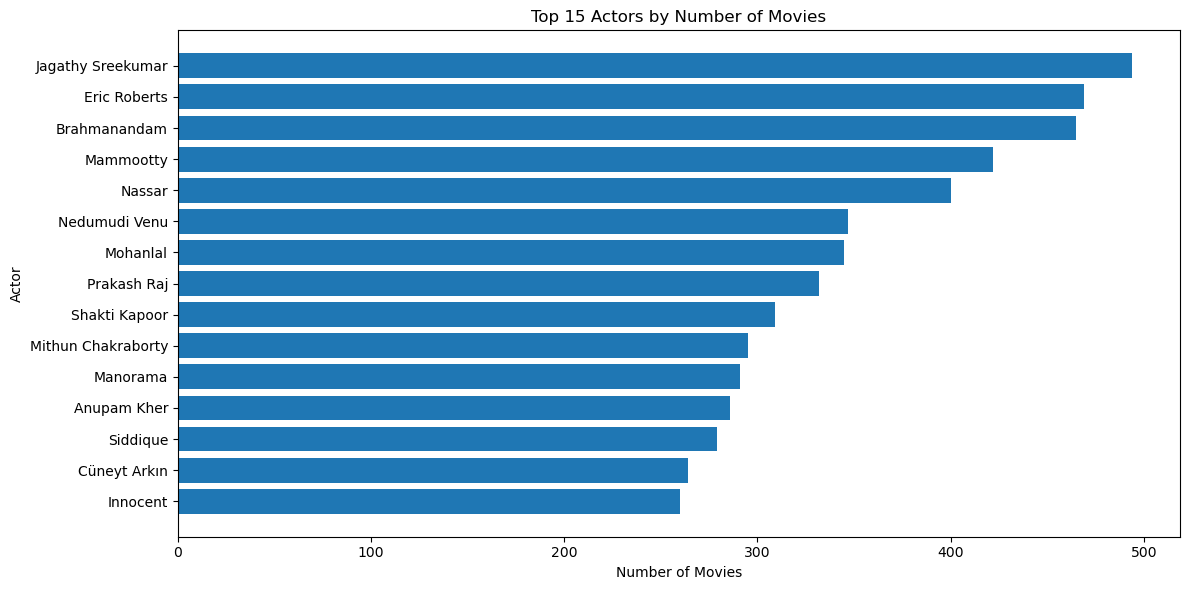

In [88]:
plt.figure(figsize=(12,6))

plt.barh(
    top_actors.index,
    top_actors.values
)

plt.xlabel("Number of Movies")
plt.ylabel("Actor")
plt.title("Top 15 Actors by Number of Movies")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [89]:
movies.to_csv(
    "../dataset/processed/movieverse_clean_dataset.csv",
    index=False
)

print("EDA Dataset Saved Successfully")
print(movies.shape)

EDA Dataset Saved Successfully
(570748, 17)
